In [7]:
from pathlib import Path
import duckdb, json
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", message=".*dayofweek.*")
warnings.filterwarnings("ignore", category=DeprecationWarning)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data").is_dir())
RAW  = ROOT / "data/raw/telefonica"
OUT  = ROOT / "data/processed/rmove"
F_M3 = OUT / "m3_mun_a_barrio.parquet"

if not F_M3.exists():
    duckdb.connect().execute(f"""
    COPY (
      SELECT CAST(day AS DATE) AS fecha, municipio_origen, barrio_destino,
             any_value(barrio_destino_name) AS barrio, SUM(viajes) AS viajes
      FROM read_csv('{RAW.as_posix()}/*/movilidad_mun_barrios_*_origen.csv',
           types={{'municipio_origen':'VARCHAR','municipio_destino':'VARCHAR',
                   'barrio_origen':'VARCHAR','barrio_destino':'VARCHAR'}}, union_by_name=true)
      WHERE municipio_destino = '08019' AND origen IN ('Regional', 'Residente')
      GROUP BY fecha, municipio_origen, barrio_destino
      HAVING SUM(viajes) > 0
    ) TO '{F_M3.as_posix()}' (FORMAT parquet)""")

m3 = pd.read_parquet(F_M3)
m3["fecha"] = pd.to_datetime(m3.fecha)
print(m3.shape, "· días:", m3.fecha.nunique(), "· municipios:", m3.municipio_origen.nunique(),
      "· barrios:", m3.barrio_destino.nunique())

(3059153, 5) · días: 971 · municipios: 302 · barrios: 73


In [2]:
cal  = pd.read_parquet(OUT / "m2_cal.parquet")
info = pd.read_parquet(OUT / "m2_info_municipios.parquet")
caos_real = pd.to_datetime(pd.read_parquet(OUT / "m2_caos_real.parquet").fecha)

# M3 sumado por municipio frente a M2 hacia Barcelona (días limpios)
F_M2 = ROOT / "data/processed/telefonica/M2.parquet"
m2_bcn = duckdb.connect().execute(f"""
    SELECT CAST(day AS DATE) AS fecha, municipio_origen, SUM(viajes) AS viajes
    FROM read_parquet('{F_M2.as_posix()}')
    WHERE municipio_destino = '08019' AND origen IN ('Regional', 'Residente')
    GROUP BY ALL""").df()
m2_bcn["fecha"] = pd.to_datetime(m2_bcn.fecha)

limpios = cal.index[cal.limpio]
a = m3[m3.fecha.isin(limpios)].groupby("municipio_origen").viajes.sum()
b = m2_bcn[m2_bcn.fecha.isin(limpios)].groupby("municipio_origen").viajes.sum()
j = pd.concat([a.rename("M3"), b.rename("M2")], axis=1).dropna()
print(f"M3 / M2 total: {j.M3.sum() / j.M2.sum():.2f} · correlación (log): "
      f"{np.corrcoef(np.log1p(j.M3), np.log1p(j.M2))[0, 1]:.3f}")

# ¿Cuántos viajes se concentran en pares municipio–barrio grandes?
mb = (m3[m3.fecha.isin(limpios)].groupby(["municipio_origen", "barrio_destino"]).viajes.sum()
      / len(limpios))
print(f"Pares con ≥ 50 viajes/día: {(mb >= 50).sum()} de {len(mb)} · "
      f"concentran el {mb[mb >= 50].sum() / mb.sum():.0%} de los viajes")

M3 / M2 total: 0.87 · correlación (log): 0.970
Pares con ≥ 50 viajes/día: 1643 de 11976 · concentran el 92% de los viajes


In [3]:
F_JSON = next(ROOT.rglob("*bcn_station_neighborhoods.json"))
J = json.load(open(F_JSON, encoding="utf-8"))
est = pd.read_csv(OUT / "estaciones_rodalies_municipio.csv", encoding="utf-8", dtype={"stop_id": str})

est_bcn = (pd.DataFrame([{"stop_id": c["station_id"], "barrio": c["respuesta"]["resultats"][0]["nom"]}
                         for c in J["consultas"] if c["dx_m"] == 0 and c["dy_m"] == 0])
             .merge(est[["stop_id", "stop_name", "lineas"]], on="stop_id", how="left"))

barrios = m3.groupby("barrio_destino").barrio.first().to_frame()
barrios["con_estacion"] = barrios.barrio.isin(est_bcn.barrio)
barrios["lineas_estacion"] = barrios.barrio.map(
    est_bcn.groupby("barrio").lineas.apply(lambda s: ",".join(sorted(set(",".join(s.dropna()).split(","))))))
barrios["viajes_dia"] = (m3[m3.fecha.isin(limpios)].groupby("barrio_destino").viajes.sum() / len(limpios)).round()

display(est_bcn)
display(barrios[barrios.con_estacion])
print(f"Barrios con estación: {barrios.con_estacion.sum()} · reciben el "
      f"{barrios.loc[barrios.con_estacion, 'viajes_dia'].sum() / barrios.viajes_dia.sum():.0%} de los viajes")

# Líneas por barrio según la red 2023–2025 (el GTFS es del horario actual)
LINEAS_BARRIO = {
    "Sants":                                 "R1,R2N,R2S,R3,R4",
    "la Dreta de l'Eixample":                "R1,R2N,R2S,R3,R4",   # Pl. Catalunya + Pg. de Gràcia
    "el Fort Pienc":                         "R1,R3,R4",           # Arc de Triomf
    "el Clot":                               "R1,R2N",
    "Sant Andreu":                           "R2N,R3,R4,R7",       # Sant Andreu + Fabra i Puig
    "Sant Pere, Santa Caterina i la Ribera": "R2N,R2S",            # Estació de França
    "la Sagrera":                            "R3,R4,R7",
    "Torre Baró":                            "R3,R4,R7",
}
barrios["lineas_estacion"] = barrios.barrio.map(LINEAS_BARRIO)
display(barrios[barrios.con_estacion])

,stop_id,barrio,stop_name,lineas
0,71801,Sants,Barcelona-Sants,"R1,R2,R2N,R2S,R4"
1,78805,la Dreta de l'Eixample,Barcelona Plaça de Catalunya,"R1,R4"
2,78804,el Fort Pienc,Barcelona Arc de Triomf,"R1,R4"
3,79009,el Clot,Barcelona El Clot,"R1,R2,R2N"
4,71802,la Dreta de l'Eixample,Barcelona-Passeig de Gràcia,"R2,R2N,R2S"
5,79004,Sant Andreu,Barcelona Sant Andreu,"R2,R2N"
6,79400,"Sant Pere, Santa Caterina i la Ribera",Barcelona Estació de França,"R2N,R2S"
7,78806,la Sagrera,Barcelona La Sagrera-Meridiana,R4
8,78802,Sant Andreu,Barcelona Fabra i Puig,"R3,R4"
9,78801,Torre Baró,Barcelona Torre Baró -Vallbona,R4


,barrio,con_estacion,lineas_estacion,viajes_dia
barrio_destino,,,,
080190104,"Sant Pere, Santa Caterina i la Ribera",True,"R2N,R2S",5346.0
080190201,el Fort Pienc,True,"R1,R4",7878.0
080190203,la Dreta de l'Eixample,True,"R1,R2,R2N,R2S,R4",66037.0
080190308,Sants,True,"R1,R2,R2N,R2S,R4",33154.0
080190811,Torre Baró,True,R4,824.0
080190904,Sant Andreu,True,"R2,R2N,R3,R4",33249.0
080190905,la Sagrera,True,R4,7582.0
080191002,el Clot,True,"R1,R2,R2N",4746.0


Barrios con estación: 8 · reciben el 25% de los viajes


,barrio,con_estacion,lineas_estacion,viajes_dia
barrio_destino,,,,
080190104,"Sant Pere, Santa Caterina i la Ribera",True,"R2N,R2S",5346.0
080190201,el Fort Pienc,True,"R1,R3,R4",7878.0
080190203,la Dreta de l'Eixample,True,"R1,R2N,R2S,R3,R4",66037.0
080190308,Sants,True,"R1,R2N,R2S,R3,R4",33154.0
080190811,Torre Baró,True,"R3,R4,R7",824.0
080190904,Sant Andreu,True,"R2N,R3,R4,R7",33249.0
080190905,la Sagrera,True,"R3,R4,R7",7582.0
080191002,el Clot,True,"R1,R2N",4746.0


In [ ]:
import pyfixest as pf

tipos = pd.read_parquet(OUT / "m2_tipos_dia.parquet").tipo
tipos.index = pd.to_datetime(tipos.index)
tipos = pd.Series(tipos.index.year.astype(str), index=tipos.index) + "-" + tipos   # tipo por año

def regresion(panel, tratados, dias, unidad="municipio_origen"):
    """Regresión DiD: tratados frente a municipios sin Rodalies, con efectos fijos."""
    ctrl = info.index[~info.rodalies]
    d = panel[panel[unidad].isin(set(tratados) | set(ctrl))
              & (panel.fecha.isin(cal.index[cal.limpio]) | panel.fecha.isin(dias))].copy()
    d["y"] = np.log(d.viajes)
    d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.day_of_week.astype(str)
    d["trat"] = (d[unidad].isin(tratados) & d.fecha.isin(dias)).astype(int)
    m = pf.feols("y ~ trat | u_dow + fecha", data=d, vcov={"CRV1": unidad})
    b, se, p = m.coef()["trat"], m.se()["trat"], m.pvalue()["trat"]
    pct = lambda x: round((np.exp(x) - 1) * 100, 1)
    return pct(b), f"[{pct(b - 1.96 * se)}, {pct(b + 1.96 * se)}]", round(p, 3)

def clustering(panel, tratados, dias, n_sim=2000, seed=0):
    """Viajes del grupo / mediana de los días limpios del mismo tipo − 1; p por remuestreo."""
    s = panel[panel.municipio_origen.isin(tratados)].groupby("fecha").viajes.sum()
    limpios = s.index[s.index.isin(cal.index[cal.limpio])]
    ratio = lambda d, excl: s[d] / s[[x for x in limpios if tipos.get(x) == tipos.get(d) and x != excl]].median() - 1
    obs = np.mean([ratio(d, None) for d in dias if d in s.index])
    rng = np.random.default_rng(seed)
    pool = {d: [x for x in limpios if tipos.get(x) == tipos.get(d)] for d in dias}
    cache = {}
    def r0(x):
        if x not in cache: cache[x] = ratio(x, x)
        return cache[x]
    sims = [np.mean([r0(rng.choice(pool[d])) for d in dias]) for _ in range(n_sim)]
    p = (np.sum(np.array(sims) <= obs) + 1) / (n_sim + 1)
    return round(obs * 100, 1), round(p, 3)

def comparar_m3(panel, grupos, dias):
    filas = {}
    for nombre, codes in grupos.items():
        codes = [c for c in codes if c in set(panel.municipio_origen)]
        c_ef, c_p = clustering(panel, codes, dias)
        r_ef, r_ic, r_p = regresion(panel, codes, dias)
        filas[nombre] = {"municipios": len(codes), "clustering_%": c_ef, "clustering_p": c_p,
                         "regresión_%": r_ef, "regresión_IC95": r_ic, "regresión_p": r_p}
    return pd.DataFrame(filas).T

# Panel: M3 sumado por municipio (como M2), mismos filtros que en M2
p_mun = m3.groupby(["municipio_origen", "fecha"], as_index=False).viajes.sum()
p_mun = p_mun[p_mun.fecha.isin(cal.index[cal.limpio].union(caos_real))]
media = p_mun[p_mun.fecha.isin(cal.index[cal.limpio])].groupby("municipio_origen").viajes.mean()
p_mun = p_mun[p_mun.municipio_origen.isin(media.index[media >= 200])]

grupos = {"Dependientes": info.index[info.dependiente],
          "Con alternativa (cercanos o con metro/FGC)": info.index[info.rodalies & ~info.dependiente]}

for titulo, dias in {"Todos los días de caos": caos_real,
                     "Huelga 17/03/2025": [pd.Timestamp("2025-03-17")],
                     "Avería 13/05/2024": [pd.Timestamp("2024-05-13")]}.items():
    print(f"\n{titulo}")
    display(comparar_m3(p_mun, grupos, pd.DatetimeIndex(dias)))


Todos los días de caos


C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)


,municipios,clustering_%,clustering_p,regresión_%,regresión_IC95,regresión_p
Dependientes,28,-7.7,0.002,-8.6,"[-14.7, -2.1]",0.012
Con alternativa (cercanos o con metro/FGC),27,-2.8,0.004,-0.7,"[-4.8, 3.5]",0.738



Huelga 17/03/2025


C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)


,municipios,clustering_%,clustering_p,regresión_%,regresión_IC95,regresión_p
Dependientes,28,-14.0,0.0,-13.9,"[-22.0, -5.0]",0.004
Con alternativa (cercanos o con metro/FGC),27,-2.9,0.137,0.1,"[-7.8, 8.7]",0.979



Avería 13/05/2024


C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)


,municipios,clustering_%,clustering_p,regresión_%,regresión_IC95,regresión_p
Dependientes,28,-11.3,0.023,-17.9,"[-27.5, -7.0]",0.003
Con alternativa (cercanos o con metro/FGC),27,1.9,0.646,-1.5,"[-8.2, 5.6]",0.665


In [5]:
# M2 con exactamente los mismos municipios que el panel de M3
p_m2 = m2_bcn[m2_bcn.fecha.isin(cal.index[cal.limpio].union(caos_real))
              & m2_bcn.municipio_origen.isin(p_mun.municipio_origen.unique())]

for titulo, dias in {"Todos los días de caos": caos_real,
                     "Huelga 17/03/2025": [pd.Timestamp("2025-03-17")],
                     "Avería 13/05/2024": [pd.Timestamp("2024-05-13")]}.items():
    print(f"\n{titulo}")
    filas = {}
    for nombre, codes in grupos.items():
        codes = [c for c in codes if c in set(p_mun.municipio_origen)]
        filas[nombre] = {"M2_%": regresion(p_m2, codes, pd.DatetimeIndex(dias))[0],
                         "M3_%": regresion(p_mun, codes, pd.DatetimeIndex(dias))[0]}
    display(pd.DataFrame(filas).T)


Todos los días de caos


C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week

,M2_%,M3_%
Dependientes,-6.1,-8.6
Con alternativa (cercanos o con metro/FGC),-1.3,-0.7



Huelga 17/03/2025


C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week

,M2_%,M3_%
Dependientes,-9.2,-13.9
Con alternativa (cercanos o con metro/FGC),0.2,0.1



Avería 13/05/2024


C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week

,M2_%,M3_%
Dependientes,-9.9,-17.9
Con alternativa (cercanos o con metro/FGC),0.2,-1.5


**Resultado H1.** Sumando todos los barrios, M3 reproduce el resultado de M2: los municipios dependientes
caen de forma significativa en los días de caos y los que tienen alternativa no cambian. Sin embargo, con
los mismos 28 municipios, las caídas de M3 son entre 1,4 y 1,8 veces mayores que las de M2. Esto se debe
a la censura por privacidad: en M3 los viajes se reparten entre 73 barrios y muchos flujos son pequeños;
un día de caos bajan de 15 y se publican como 0, y la caída se amplifica. Por eso, en M3 solo se
interpretan la dirección, la significancia y las comparaciones entre grupos de barrios, no la magnitud
absoluta.

In [6]:
# Pares municipio–barrio con ≥ 50 viajes/día en días limpios
lim = cal.index[cal.limpio]
media_par = m3[m3.fecha.isin(lim)].groupby(["municipio_origen", "barrio_destino"]).viajes.sum() / len(lim)
pares_ok = media_par[media_par >= 50].index

m3_grandes = m3.set_index(["municipio_origen", "barrio_destino"]).loc[lambda x: x.index.isin(pares_ok)].reset_index()
p_mun_g = (m3_grandes.groupby(["municipio_origen", "fecha"], as_index=False).viajes.sum()
             .loc[lambda x: x.municipio_origen.isin(p_mun.municipio_origen.unique())])

for titulo, dias in {"Todos los días de caos": caos_real,
                     "Huelga 17/03/2025": [pd.Timestamp("2025-03-17")],
                     "Avería 13/05/2024": [pd.Timestamp("2024-05-13")]}.items():
    print(f"\n{titulo}")
    filas = {}
    for nombre, codes in grupos.items():
        codes = [c for c in codes if c in set(p_mun.municipio_origen)]
        filas[nombre] = {"M2_%": regresion(p_m2, codes, pd.DatetimeIndex(dias))[0],
                         "M3_todos_%": regresion(p_mun, codes, pd.DatetimeIndex(dias))[0],
                         "M3_pares≥50_%": regresion(p_mun_g, codes, pd.DatetimeIndex(dias))[0]}
    display(pd.DataFrame(filas).T)


Todos los días de caos


C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week

,M2_%,M3_todos_%,M3_pares≥50_%
Dependientes,-6.1,-8.6,-14.7
Con alternativa (cercanos o con metro/FGC),-1.3,-0.7,-0.3



Huelga 17/03/2025


C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week

,M2_%,M3_todos_%,M3_pares≥50_%
Dependientes,-9.2,-13.9,-15.5
Con alternativa (cercanos o con metro/FGC),0.2,0.1,-0.5



Avería 13/05/2024


C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["u_dow"] = d[unidad].astype(str) + "_" + d.fecha.dt.dayofweek.astype(str)
C:\Users\marti\AppData\Local\Temp\ipykernel_10660\3153806952.py:13: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week

,M2_%,M3_todos_%,M3_pares≥50_%
Dependientes,-9.9,-17.9,-34.1
Con alternativa (cercanos o con metro/FGC),0.2,-1.5,1.5


In [8]:
def regresion_h2(m3, tratados, dias, min_viajes=200):
    """Efecto hacia barrios con y sin estación, y test de la diferencia."""
    lim = cal.index[cal.limpio]
    p = (m3.assign(est=m3.barrio_destino.map(barrios.con_estacion).map({True: "con", False: "sin"}))
           .groupby(["municipio_origen", "est", "fecha"], as_index=False).viajes.sum())
    p = p[p.fecha.isin(lim.union(dias))]
    media = p[p.fecha.isin(lim)].groupby(["municipio_origen", "est"]).viajes.mean()
    ok = media[media >= min_viajes].index
    p = p[pd.MultiIndex.from_frame(p[["municipio_origen", "est"]]).isin(ok)]
    ctrl = info.index[~info.rodalies]
    p = p[p.municipio_origen.isin(set(tratados) | set(ctrl))].copy()
    p["y"] = np.log(p.viajes)
    p["u_dow"] = p.municipio_origen + "_" + p.est + "_" + p.fecha.dt.day_of_week.astype(str)
    caos = p.fecha.isin(dias) & p.municipio_origen.isin(tratados)
    p["trat_con"] = (caos & (p.est == "con")).astype(int)
    p["trat_sin"] = (caos & (p.est == "sin")).astype(int)
    p["trat"] = caos.astype(int)
    fe = "u_dow + fecha:est"          # efecto fijo día × tipo de barrio
    vc = {"CRV1": "municipio_origen"}
    m1 = pf.feols(f"y ~ trat_con + trat_sin | {fe}", data=p, vcov=vc)   # efecto en cada tipo
    m2 = pf.feols(f"y ~ trat + trat_con | {fe}", data=p, vcov=vc)       # trat_con = diferencia con − sin
    pct = lambda x: round((np.exp(x) - 1) * 100, 1)
    fila = lambda m, k: {"efecto_%": pct(m.coef()[k]),
                         "IC95": f"[{pct(m.coef()[k] - 1.96 * m.se()[k])}, {pct(m.coef()[k] + 1.96 * m.se()[k])}]",
                         "p": round(m.pvalue()[k], 3)}
    n = p[p.municipio_origen.isin(tratados)].groupby("est").municipio_origen.nunique()
    print(f"Municipios tratados (≥ {min_viajes} viajes/día): con estación {n.get('con', 0)}, sin estación {n.get('sin', 0)}")
    return pd.DataFrame({"Hacia barrios CON estación": fila(m1, "trat_con"),
                         "Hacia barrios SIN estación": fila(m1, "trat_sin"),
                         "Diferencia relativa (con frente a sin)": fila(m2, "trat_con")}).T

for titulo, dias in {"Todos los días de caos": caos_real,
                     "Huelga 17/03/2025": [pd.Timestamp("2025-03-17")],
                     "Avería 13/05/2024": [pd.Timestamp("2024-05-13")]}.items():
    print(f"\n{titulo} · DEPENDIENTES")
    display(regresion_h2(m3, info.index[info.dependiente], pd.DatetimeIndex(dias)))


Todos los días de caos · DEPENDIENTES
Municipios tratados (≥ 200 viajes/día): con estación 21, sin estación 21


,efecto_%,IC95,p
Hacia barrios CON estación,-19.0,"[-26.8, -10.4]",0.0
Hacia barrios SIN estación,1.8,"[-5.0, 9.2]",0.61
Diferencia relativa (con frente a sin),-20.5,"[-28.1, -12.1]",0.0



Huelga 17/03/2025 · DEPENDIENTES
Municipios tratados (≥ 200 viajes/día): con estación 21, sin estación 21


,efecto_%,IC95,p
Hacia barrios CON estación,-18.4,"[-28.8, -6.3]",0.005
Hacia barrios SIN estación,-10.1,"[-18.4, -1.0]",0.033
Diferencia relativa (con frente a sin),-9.2,"[-22.4, 6.3]",0.235



Avería 13/05/2024 · DEPENDIENTES
Municipios tratados (≥ 200 viajes/día): con estación 21, sin estación 21


,efecto_%,IC95,p
Hacia barrios CON estación,-26.6,"[-39.7, -10.6]",0.003
Hacia barrios SIN estación,2.8,"[-9.4, 16.6]",0.674
Diferencia relativa (con frente a sin),-28.6,"[-42.3, -11.5]",0.003


In [9]:
from scipy.stats import norm

def efectos_barrio(m3, tratados, DIA, min_viajes=50):
    """Efecto del día DIA en los viajes de 'tratados' hacia cada barrio (DiD frente a municipios de control)."""
    DIA = pd.Timestamp(DIA)
    lim = cal.index[cal.limpio]
    ctrl = info.index[~info.rodalies]
    g = m3[m3.fecha.isin(lim.union([DIA]))].copy()
    g["grupo"] = np.where(g.municipio_origen.isin(tratados), "trat",
                          np.where(g.municipio_origen.isin(ctrl), "ctrl", None))
    g = g.dropna(subset=["grupo"]).groupby(["barrio_destino", "grupo", "fecha"]).viajes.sum().unstack("grupo")
    g = g.dropna()                                   # días con viajes de los dos grupos
    y = np.log(g)
    dow = y.index.get_level_values("fecha").day_of_week
    # desviación respecto a la media del mismo barrio y día de la semana (en días limpios)
    es_lim = y.index.get_level_values("fecha").isin(lim)
    base = y[es_lim].groupby([y[es_lim].index.get_level_values("barrio_destino"), dow[es_lim]]).mean()
    clave = pd.MultiIndex.from_arrays([y.index.get_level_values("barrio_destino"), dow])
    dev = y - base.reindex(clave).to_numpy()
    did = dev.trat - dev.ctrl                        # diferencia tratados − control
    sd = did[es_lim].groupby(level="barrio_destino").std()
    ef = did.xs(DIA, level="fecha")
    r = barrios.copy()
    r["viajes_trat_dia"] = g.trat[es_lim].groupby(level="barrio_destino").mean().round()
    r["efecto_%"] = ((np.exp(ef) - 1) * 100).round(1)
    r["z"] = (ef / sd).round(2)
    r["p"] = (2 * (1 - norm.cdf(r.z.abs()))).round(3)
    return r[r.viajes_trat_dia >= min_viajes].dropna(subset=["efecto_%"]).sort_values("efecto_%")

def grafico_barrios(r, titulo, n=20):
    t = pd.concat([r.head(n // 2), r.tail(n // 2)]).drop_duplicates().iloc[::-1]
    col = np.where(t.con_estacion, "C3", "C0")
    alpha = np.where(t.p < 0.05, 1.0, 0.35)
    fig, ax = plt.subplots(figsize=(10, 0.35 * len(t) + 1.5))
    for i, (_, f) in enumerate(t.iterrows()):
        ax.barh(i, f["efecto_%"], color=col[i], alpha=alpha[i])
        etiqueta = f"p={f.p:.2f}" + (f"  [{f.lineas_estacion}]" if f.con_estacion else "")
        ax.text(f["efecto_%"] + (0.5 if f["efecto_%"] >= 0 else -0.5), i, etiqueta, va="center",
                ha="left" if f["efecto_%"] >= 0 else "right", fontsize=7)
    ax.set_yticks(range(len(t))); ax.set_yticklabels(t.barrio)
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel("% cambio de viajes (afectados frente a control)")
    ax.set_title(titulo + "\nrojo = barrio con estación · azul = sin estación · color intenso = p < 0,05")
    lim_x = t["efecto_%"].abs().max() + 15
    ax.set_xlim(-lim_x, lim_x)
    plt.tight_layout(); plt.show()


Huelga 17/03/2025 · todos los dependientes · 55 barrios · significativos: 9


,barrio,con_estacion,lineas_estacion,viajes_trat_dia,efecto_%,z,p
barrio_destino,,,,,,,
080190805,la Guineueta,False,NaN,61.0,-76.5,-2.39,0.017
080190303,la Marina de Port,False,NaN,421.0,-46.0,-3.11,0.002
080190604,la Vila de Gràcia,False,NaN,694.0,-45.1,-1.92,0.055
080190809,la Prosperitat,False,NaN,257.0,-43.0,-1.22,0.222
080190305,Hostafrancs,False,NaN,271.0,-42.2,-2.05,0.040
080190708,Montbau,False,NaN,406.0,-40.8,-1.67,0.095
080190711,Horta,False,NaN,766.0,-38.3,-1.84,0.066
080191007,el Besòs i el Maresme,False,NaN,396.0,-35.8,-1.34,0.180
080190402,la Maternitat i Sant Ramon,False,NaN,1355.0,-34.5,-1.84,0.066


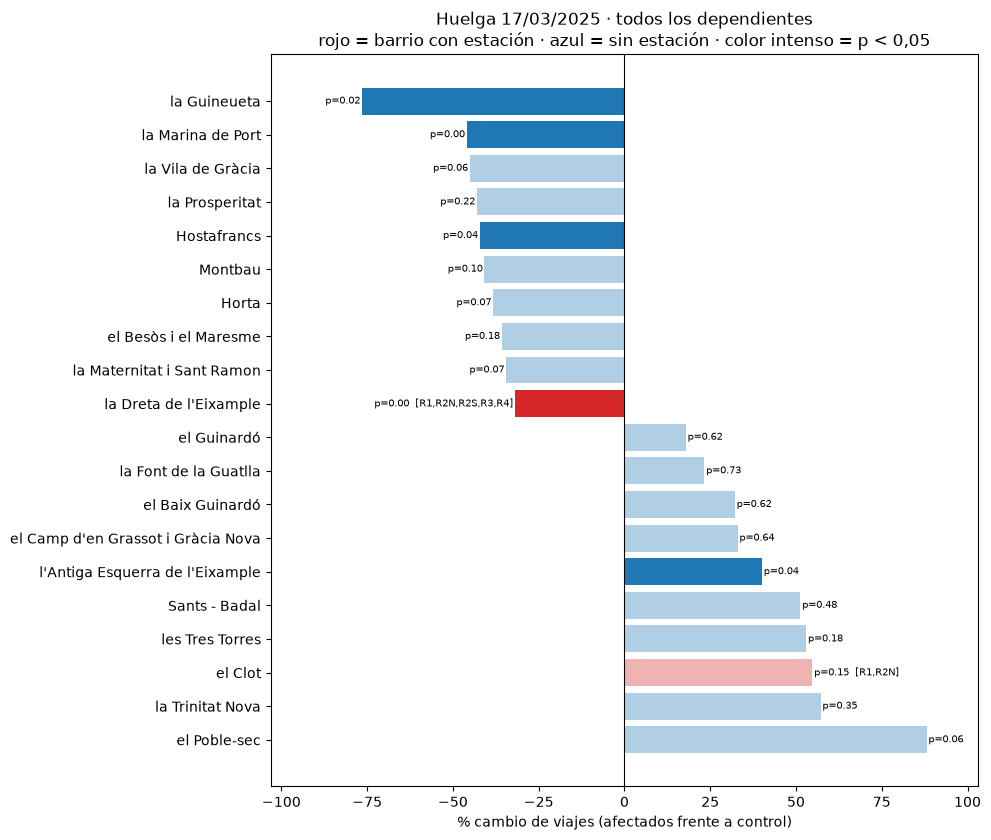


Avería 13/05/2024 · todos los dependientes · 57 barrios · significativos: 4


,barrio,con_estacion,lineas_estacion,viajes_trat_dia,efecto_%,z,p
barrio_destino,,,,,,,
080190605,el Camp d'en Grassot i Gràcia Nova,False,NaN,82.0,-82.8,-2.89,0.004
080190907,Navas,False,NaN,82.0,-61.0,-1.69,0.091
080190904,Sant Andreu,True,"R2N,R3,R4,R7",3202.0,-48.2,-2.11,0.035
080191001,el Camp de l'Arpa del Clot,False,NaN,206.0,-40.2,-1.55,0.121
080190901,la Trinitat Vella,False,NaN,775.0,-36.8,-1.56,0.119
080190308,Sants,True,"R1,R2N,R2S,R3,R4",5535.0,-36.8,-4.15,0.000
080191007,el Besòs i el Maresme,False,NaN,396.0,-26.6,-0.93,0.352
080190201,el Fort Pienc,True,"R1,R3,R4",957.0,-24.2,-1.88,0.060
080190402,la Maternitat i Sant Ramon,False,NaN,1355.0,-23.0,-1.14,0.254


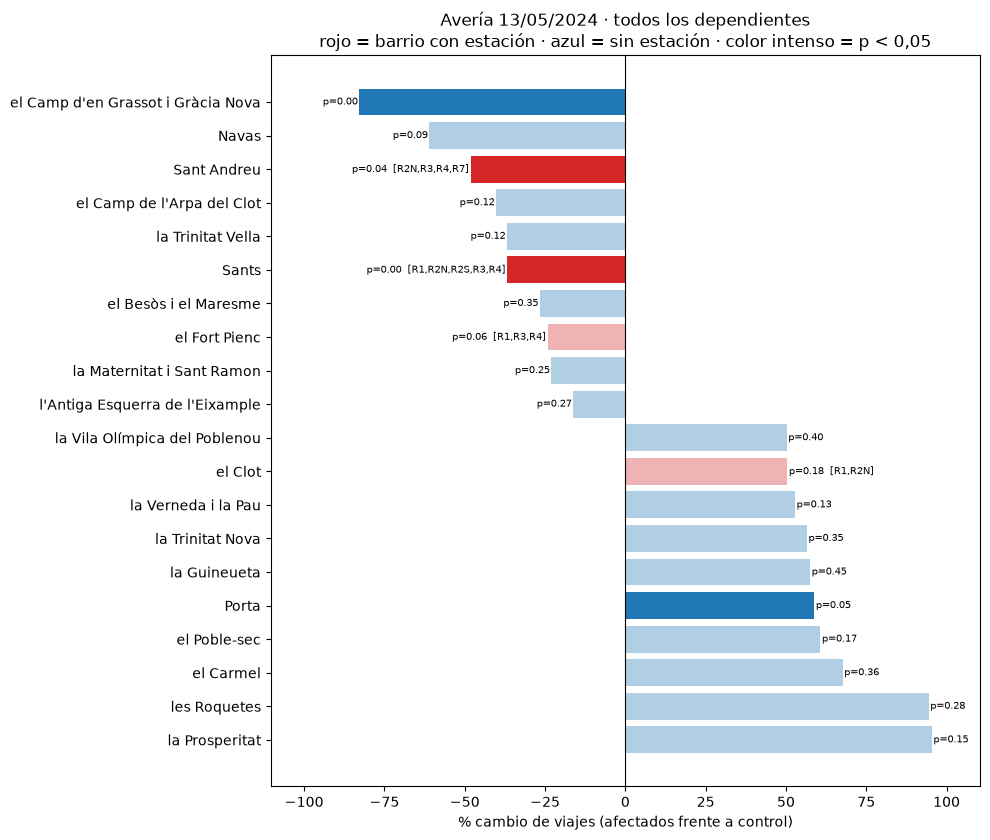


Avería 13/05/2024 · solo dependientes de la R1 · 41 barrios · significativos: 2


,barrio,con_estacion,lineas_estacion,viajes_trat_dia,efecto_%,z,p
barrio_destino,,,,,,,
080190308,Sants,True,"R1,R2N,R2S,R3,R4",1272.0,-81.7,-5.31,0.000
080190503,les Tres Torres,False,NaN,68.0,-75.3,-2.21,0.027
080190402,la Maternitat i Sant Ramon,False,NaN,140.0,-55.6,-1.46,0.144
080190901,la Trinitat Vella,False,NaN,458.0,-52.6,-1.55,0.121
080190904,Sant Andreu,True,"R2N,R3,R4,R7",1291.0,-51.8,-1.14,0.254
080190403,Pedralbes,False,NaN,85.0,-45.0,-0.97,0.332
080190104,"Sant Pere, Santa Caterina i la Ribera",True,"R2N,R2S",218.0,-36.3,-1.70,0.089
080190401,les Corts,False,NaN,241.0,-33.8,-1.17,0.242
080191001,el Camp de l'Arpa del Clot,False,NaN,108.0,-32.8,-0.85,0.395


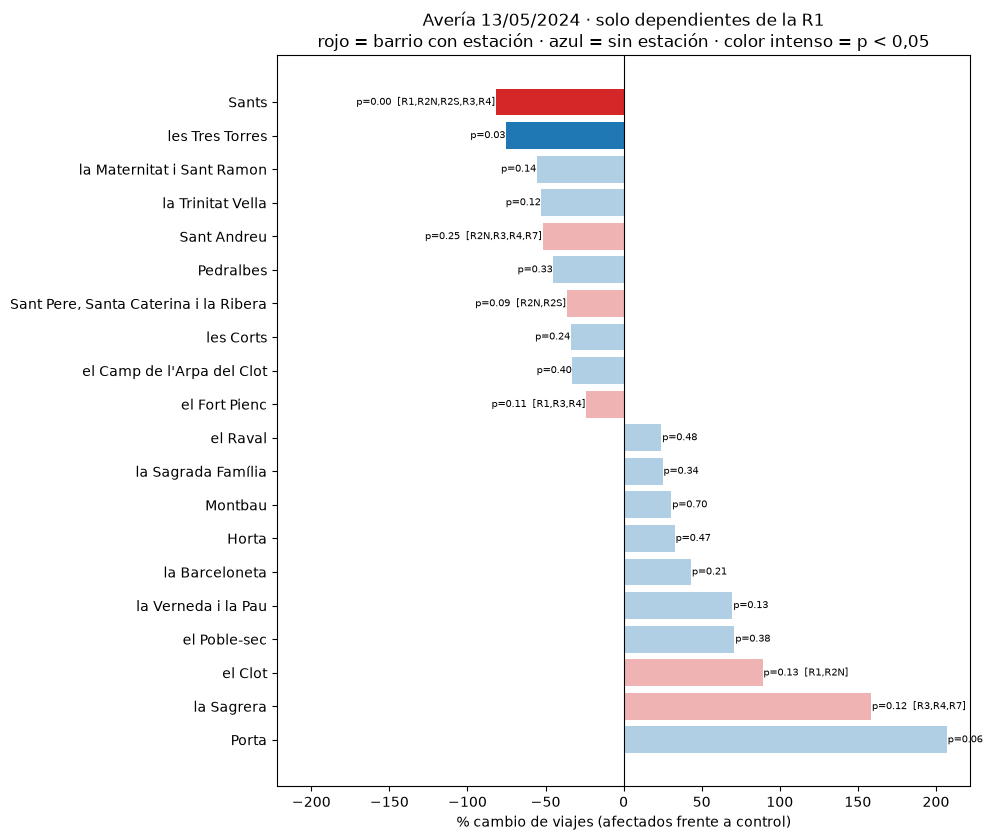

In [10]:
dep    = info.index[info.dependiente]
dep_r1 = info.index[info.dependiente & info.lineas.str.contains("R1")]

casos = {
    "Huelga 17/03/2025 · todos los dependientes":  (dep,    "2025-03-17"),
    "Avería 13/05/2024 · todos los dependientes":  (dep,    "2024-05-13"),
    "Avería 13/05/2024 · solo dependientes de la R1": (dep_r1, "2024-05-13"),
}
res_h3 = {}
for titulo, (trat, dia) in casos.items():
    r = efectos_barrio(m3, trat, dia)
    res_h3[titulo] = r
    print(f"\n{titulo} · {len(r)} barrios · significativos: {(r.p < 0.05).sum()}")
    display(r[["barrio", "con_estacion", "lineas_estacion", "viajes_trat_dia", "efecto_%", "z", "p"]].head(10))
    grafico_barrios(r, titulo)

In [11]:
def regresion_tipos(m3, tratados, dias, tipo_barrio, ref, min_viajes=200):
    """Efecto del caos según el tipo de barrio de destino, y diferencia de cada tipo frente a 'ref'."""
    lim = cal.index[cal.limpio]
    dias = pd.DatetimeIndex(dias)
    p = (m3.assign(tipo=m3.barrio_destino.map(tipo_barrio))
           .groupby(["municipio_origen", "tipo", "fecha"], as_index=False).viajes.sum())
    p = p[p.fecha.isin(lim.union(dias))]
    media = p[p.fecha.isin(lim)].groupby(["municipio_origen", "tipo"]).viajes.mean()
    ok = media[media >= min_viajes].index
    p = p[pd.MultiIndex.from_frame(p[["municipio_origen", "tipo"]]).isin(ok)]
    ctrl = info.index[~info.rodalies]
    p = p[p.municipio_origen.isin(set(tratados) | set(ctrl))].copy()
    p["y"] = np.log(p.viajes)
    p["u_dow"] = p.municipio_origen + "_" + p.tipo + "_" + p.fecha.dt.day_of_week.astype(str)
    caos = p.fecha.isin(dias) & p.municipio_origen.isin(tratados)
    tipos_ = sorted(p.tipo.unique())
    nom = {t: f"t{i}" for i, t in enumerate(tipos_)}
    for t in tipos_:
        p[nom[t]] = (caos & (p.tipo == t)).astype(int)
    p["trat"] = caos.astype(int)
    fe, vc = "u_dow + fecha:tipo", {"CRV1": "municipio_origen"}
    m1 = pf.feols("y ~ " + " + ".join(nom.values()) + f" | {fe}", data=p, vcov=vc)
    otros = [nom[t] for t in tipos_ if t != ref]
    m2 = pf.feols("y ~ trat + " + " + ".join(otros) + f" | {fe}", data=p, vcov=vc)  # diferencias frente a ref
    pct = lambda x: round((np.exp(x) - 1) * 100, 1)
    n = p[p.municipio_origen.isin(tratados)].groupby("tipo").municipio_origen.nunique()
    filas = {}
    for t in tipos_:
        k = nom[t]
        f = {"municipios": n.get(t, 0), "efecto_%": pct(m1.coef()[k]),
             "IC95": f"[{pct(m1.coef()[k] - 1.96 * m1.se()[k])}, {pct(m1.coef()[k] + 1.96 * m1.se()[k])}]",
             "p": round(m1.pvalue()[k], 3)}
        if t != ref:
            f[f"dif. frente a «{ref}» %"] = pct(m2.coef()[k]); f["p_dif"] = round(m2.pvalue()[k], 3)
        filas[t] = f
    return pd.DataFrame(filas).T

def tipo_por_linea(linea):
    """Clasifica los barrios: con estación de 'linea', con estación de otras líneas o sin estación."""
    return barrios.apply(lambda b: f"Estación {linea}" if b.con_estacion and linea in str(b.lineas_estacion)
                         else ("Estación otras líneas" if b.con_estacion else "Sin estación"), axis=1)

print("Avería 13/05/2024 · dependientes de la R1")
display(regresion_tipos(m3, dep_r1, ["2024-05-13"], tipo_por_linea("R1"), ref="Sin estación"))

print("\nAvería 13/05/2024 · todos los dependientes")
display(regresion_tipos(m3, dep, ["2024-05-13"], tipo_por_linea("R1"), ref="Sin estación"))

Avería 13/05/2024 · dependientes de la R1


,municipios,efecto_%,IC95,p,dif. frente a «Sin estación» %,p_dif
Estación R1,8,-43.2,"[-59.0, -21.1]",0.001,-36.4,0.009
Estación otras líneas,2,-47.0,"[-79.5, 36.6]",0.194,-40.7,0.276
Sin estación,7,-10.7,"[-21.6, 1.8]",0.096,NaN,NaN



Avería 13/05/2024 · todos los dependientes


,municipios,efecto_%,IC95,p,dif. frente a «Sin estación» %,p_dif
Estación R1,18,-24.5,"[-39.7, -5.5]",0.016,-26.5,0.013
Estación otras líneas,6,-35.2,"[-59.8, 4.3]",0.078,-37.0,0.065
Sin estación,21,2.8,"[-9.5, 16.7]",0.675,NaN,NaN


In [12]:
for titulo, r in res_h3.items():
    print(f"\n{titulo}")
    display(r[r.con_estacion][["barrio", "lineas_estacion", "viajes_trat_dia", "efecto_%", "p"]])


Huelga 17/03/2025 · todos los dependientes


,barrio,lineas_estacion,viajes_trat_dia,efecto_%,p
barrio_destino,,,,,
080190203,la Dreta de l'Eixample,"R1,R2N,R2S,R3,R4",8451.0,-31.9,0.002
080190905,la Sagrera,"R3,R4,R7",425.0,-30.6,0.153
080190904,Sant Andreu,"R2N,R3,R4,R7",3202.0,-28.5,0.280
080190104,"Sant Pere, Santa Caterina i la Ribera","R2N,R2S",578.0,-13.1,0.447
080190308,Sants,"R1,R2N,R2S,R3,R4",5535.0,-8.8,0.407
080190201,el Fort Pienc,"R1,R3,R4",957.0,2.6,0.865
080191002,el Clot,"R1,R2N",258.0,54.8,0.153



Avería 13/05/2024 · todos los dependientes


,barrio,lineas_estacion,viajes_trat_dia,efecto_%,p
barrio_destino,,,,,
080190904,Sant Andreu,"R2N,R3,R4,R7",3202.0,-48.2,0.035
080190308,Sants,"R1,R2N,R2S,R3,R4",5535.0,-36.8,0.000
080190201,el Fort Pienc,"R1,R3,R4",957.0,-24.2,0.060
080190104,"Sant Pere, Santa Caterina i la Ribera","R2N,R2S",578.0,-15.8,0.352
080190203,la Dreta de l'Eixample,"R1,R2N,R2S,R3,R4",8451.0,-13.4,0.238
080190905,la Sagrera,"R3,R4,R7",425.0,50.1,0.112
080191002,el Clot,"R1,R2N",258.0,50.4,0.180



Avería 13/05/2024 · solo dependientes de la R1


,barrio,lineas_estacion,viajes_trat_dia,efecto_%,p
barrio_destino,,,,,
080190308,Sants,"R1,R2N,R2S,R3,R4",1272.0,-81.7,0.000
080190904,Sant Andreu,"R2N,R3,R4,R7",1291.0,-51.8,0.254
080190104,"Sant Pere, Santa Caterina i la Ribera","R2N,R2S",218.0,-36.3,0.089
080190201,el Fort Pienc,"R1,R3,R4",666.0,-23.9,0.110
080190203,la Dreta de l'Eixample,"R1,R2N,R2S,R3,R4",3695.0,-16.2,0.072
080191002,el Clot,"R1,R2N",137.0,89.0,0.131
080190905,la Sagrera,"R3,R4,R7",76.0,158.5,0.121


In [13]:
F_M3V = OUT / "m3_barrio_a_mun.parquet"

if not F_M3V.exists():
    duckdb.connect().execute(f"""
    COPY (
      SELECT CAST(day AS DATE) AS fecha,
             municipio_destino AS municipio_origen,      -- municipio al que se vuelve
             barrio_origen     AS barrio_destino,        -- barrio de Barcelona desde el que se sale
             any_value(barrio_origen_name) AS barrio, SUM(viajes) AS viajes
      FROM read_csv('{RAW.as_posix()}/*/movilidad_mun_barrios_*_origen.csv',
           types={{'municipio_origen':'VARCHAR','municipio_destino':'VARCHAR',
                   'barrio_origen':'VARCHAR','barrio_destino':'VARCHAR'}}, union_by_name=true)
      WHERE municipio_origen = '08019' AND municipio_destino <> '08019'
        AND origen IN ('Regional', 'Residente')
      GROUP BY 1, 2, 3
      HAVING SUM(viajes) > 0
    ) TO '{F_M3V.as_posix()}' (FORMAT parquet)""")

m3v = pd.read_parquet(F_M3V)
m3v["fecha"] = pd.to_datetime(m3v.fecha)
lim = cal.index[cal.limpio]
print(m3v.shape, "· vuelta / ida (días limpios):",
      round(m3v[m3v.fecha.isin(lim)].viajes.sum() / m3[m3.fecha.isin(lim)].viajes.sum(), 3))

(3094274, 5) · vuelta / ida (días limpios): 1.006


In [14]:
# Panel de vuelta sumado por municipio (como p_mun)
p_mun_v = m3v.groupby(["municipio_origen", "fecha"], as_index=False).viajes.sum()
p_mun_v = p_mun_v[p_mun_v.fecha.isin(lim.union(caos_real))]
media_v = p_mun_v[p_mun_v.fecha.isin(lim)].groupby("municipio_origen").viajes.mean()
p_mun_v = p_mun_v[p_mun_v.municipio_origen.isin(media_v.index[media_v >= 200])]

casos = {"Todos los días de caos": caos_real,
         "Huelga 17/03/2025": pd.DatetimeIndex(["2025-03-17"]),
         "Avería 13/05/2024": pd.DatetimeIndex(["2024-05-13"])}

for titulo, dias in casos.items():
    print(f"\n===== {titulo} =====")
    print("H1 · VUELTA (todos los barrios)")
    display(comparar_m3(p_mun_v, grupos, dias))
    print("H2 · IDA")
    display(regresion_h2(m3, dep, dias))
    print("H2 · VUELTA")
    display(regresion_h2(m3v, dep, dias))


===== Todos los días de caos =====
H1 · VUELTA (todos los barrios)


,municipios,clustering_%,clustering_p,regresión_%,regresión_IC95,regresión_p
Dependientes,29,-7.7,0.0,-5.9,"[-12.4, 1.1]",0.099
Con alternativa (cercanos o con metro/FGC),27,-3.7,0.0,0.5,"[-3.9, 5.1]",0.83


H2 · IDA
Municipios tratados (≥ 200 viajes/día): con estación 21, sin estación 21


,efecto_%,IC95,p
Hacia barrios CON estación,-19.0,"[-26.8, -10.4]",0.0
Hacia barrios SIN estación,1.8,"[-5.0, 9.2]",0.61
Diferencia relativa (con frente a sin),-20.5,"[-28.1, -12.1]",0.0


H2 · VUELTA
Municipios tratados (≥ 200 viajes/día): con estación 22, sin estación 23


,efecto_%,IC95,p
Hacia barrios CON estación,-18.3,"[-27.5, -8.0]",0.001
Hacia barrios SIN estación,4.9,"[-0.7, 10.8]",0.091
Diferencia relativa (con frente a sin),-22.2,"[-30.7, -12.6]",0.0


... (8 outputs left out)

H2 · IDA
Municipios tratados (≥ 200 viajes/día): con estación 21, sin estación 21


,efecto_%,IC95,p
Hacia barrios CON estación,-26.6,"[-39.7, -10.6]",0.003
Hacia barrios SIN estación,2.8,"[-9.4, 16.6]",0.674
Diferencia relativa (con frente a sin),-28.6,"[-42.3, -11.5]",0.003


H2 · VUELTA
Municipios tratados (≥ 200 viajes/día): con estación 22, sin estación 23


,efecto_%,IC95,p
Hacia barrios CON estación,-32.0,"[-46.6, -13.5]",0.002
Hacia barrios SIN estación,3.1,"[-7.8, 15.3]",0.592
Diferencia relativa (con frente a sin),-34.1,"[-48.4, -15.8]",0.001


In [18]:
# 1) Tipos de día del clustering de M2 (días limpios y de caos)
tipos = pd.read_parquet(OUT / "m2_tipos_dia.parquet").tipo
tipos.index = pd.to_datetime(tipos.index)
tipos = pd.Series(tipos.index.year.astype(str), index=tipos.index) + "-" + tipos

# 2) Volumen de control para TODOS los días (municipios sin Rodalies, desde M2)
lim = cal.index[cal.limpio]
ctrl = info.index[~info.rodalies]
vol_all = m2_bcn[m2_bcn.municipio_origen.isin(ctrl)].groupby("fecha").viajes.sum()
lv = np.log(vol_all)

def tipo_nuevo(d):
    """Tipo cuyo centro (media del log del volumen de control en días limpios del mismo año) está más cerca."""
    ref = tipos[(tipos.index.year == d.year) & tipos.index.isin(lim)]
    centros = lv.reindex(ref.index).groupby(ref.values).mean()
    return (centros - lv[d]).abs().idxmin()

# Comprobación: ¿esta regla reproduce los tipos originales de los días limpios?
muestra = [d for d in lim if d in lv.index and d in tipos.index]
print(f"Coincidencia con los tipos de M2: {np.mean([tipo_nuevo(d) == tipos[d] for d in muestra]):.0%}")

# 3) Asignar tipo a los días extra
dias_extra = pd.to_datetime(["2024-02-19"])
for d in dias_extra:
    tipos[d] = tipo_nuevo(d)
    print(d.date(), "→", tipos[d])

# 4) Reconstruir p_mun incluyendo los días extra
dias_panel = lim.union(caos_real).union(dias_extra)
p_mun = m3.groupby(["municipio_origen", "fecha"], as_index=False).viajes.sum()
p_mun = p_mun[p_mun.fecha.isin(dias_panel)]
media = p_mun[p_mun.fecha.isin(lim)].groupby("municipio_origen").viajes.mean()
p_mun = p_mun[p_mun.municipio_origen.isin(media.index[media >= 200])]

Coincidencia con los tipos de M2: 100%
2024-02-19 → 2024-A


In [19]:
def deps_linea(linea):
    return info.index[info.dependiente & info.lineas.str.contains(linea)]

casos_extra = {
    "Huelga 17/03/2025":          ("2025-03-17", dep),
    "Huelga 26/03/2025":          ("2025-03-26", dep),
    "Huelga 01/04/2025":          ("2025-04-01", dep),
    "Avería R1 13/05/2024":       ("2024-05-13", deps_linea("R1")),
    "Robo cable R3 19/02/2024":   ("2024-02-19", deps_linea("R3")),
    "19/02/2024 · placebo R1":    ("2024-02-19", deps_linea("R1")),   # la R1 funcionaba con normalidad
    "19/02/2024 · placebo R2S":   ("2024-02-19", deps_linea("R2S")),
}

# Comprobar que ningún día cae en finde, festivo, verano o mal tiempo
cols = [c for c in ["finde", "festivo", "verano", "mal_tiempo", "limpio"] if c in cal.columns]
display(cal.loc[pd.to_datetime(sorted({d for d, _ in casos_extra.values()})), cols])

filas = []
for nombre, (dia, trat) in casos_extra.items():
    d = pd.DatetimeIndex([dia])
    tot = comparar_m3(p_mun, {"g": trat}, d).iloc[0]
    h2i = regresion_h2(m3, trat, d)
    h2v = regresion_h2(m3v, trat, d)
    filas.append({
        "caso": nombre, "municipios": tot.municipios,
        "total_%": tot["regresión_%"], "total_p": tot["regresión_p"],
        "ida_CON_%": h2i.iloc[0]["efecto_%"], "ida_SIN_%": h2i.iloc[1]["efecto_%"], "ida_dif_p": h2i.iloc[2]["p"],
        "vuelta_CON_%": h2v.iloc[0]["efecto_%"], "vuelta_SIN_%": h2v.iloc[1]["efecto_%"], "vuelta_dif_p": h2v.iloc[2]["p"],
    })
display(pd.DataFrame(filas).set_index("caso"))

,finde,festivo,verano,mal_tiempo,limpio
2024-02-19,False,False,False,False,False
2024-05-13,False,False,False,False,False
2025-03-17,False,False,False,False,False
2025-03-26,False,False,False,False,False
2025-04-01,False,False,False,False,False


Municipios tratados (≥ 200 viajes/día): con estación 21, sin estación 21
Municipios tratados (≥ 200 viajes/día): con estación 22, sin estación 23
Municipios tratados (≥ 200 viajes/día): con estación 21, sin estación 21
Municipios tratados (≥ 200 viajes/día): con estación 22, sin estación 23
Municipios tratados (≥ 200 viajes/día): con estación 21, sin estación 21
Municipios tratados (≥ 200 viajes/día): con estación 22, sin estación 23
Municipios tratados (≥ 200 viajes/día): con estación 9, sin estación 7
Municipios tratados (≥ 200 viajes/día): con estación 9, sin estación 8
Municipios tratados (≥ 200 viajes/día): con estación 4, sin estación 4
Municipios tratados (≥ 200 viajes/día): con estación 5, sin estación 4
Municipios tratados (≥ 200 viajes/día): con estación 9, sin estación 7
Municipios tratados (≥ 200 viajes/día): con estación 9, sin estación 8
Municipios tratados (≥ 200 viajes/día): con estación 4, sin estación 4
Municipios tratados (≥ 200 viajes/día): con estación 4, sin estac

,municipios,total_%,total_p,ida_CON_%,ida_SIN_%,ida_dif_p,vuelta_CON_%,vuelta_SIN_%,vuelta_dif_p
caso,,,,,,,,,
Huelga 17/03/2025,28,-13.9,0.004,-18.4,-10.1,0.235,-14.1,4.1,0.018
Huelga 26/03/2025,28,-0.6,0.919,-10.1,5.6,0.004,-7.4,4.9,0.095
Huelga 01/04/2025,28,-1.2,0.773,-20.4,10.1,0.000,-17.9,7.5,0.002
Avería R1 13/05/2024,11,-34.1,0.000,-45.2,-10.7,0.003,-44.2,-9.9,0.000
Robo cable R3 19/02/2024,5,8.9,0.717,-29.8,53.7,0.063,-19.3,61.2,0.077
19/02/2024 · placebo R1,11,-7.8,0.299,0.7,-15.5,0.049,8.1,-15.0,0.053
19/02/2024 · placebo R2S,4,1.8,0.736,2.3,3.0,0.880,3.1,4.3,0.771


In [21]:
import re

# 1) Leer los días afectados del Excel
F_INC = next(ROOT.rglob("Incidencias graves Rodalies*.xlsx"))
dias_inc = pd.read_excel(F_INC, sheet_name="Días afectados")
col = lambda clave: next(c for c in dias_inc.columns if clave.lower() in str(c).lower())
c_fecha, c_id, c_afect, c_prio = col("fecha"), col("ranking"), col("afectación"), col("prioritaria")
dias_inc[c_fecha] = pd.to_datetime(dias_inc[c_fecha])

LINEAS = ["R1", "R2N", "R2S", "R3", "R4", "R7"]
def lineas_de_texto(t):
    t = str(t).upper().replace("R2 SUD", "R2S").replace("R2 NORD", "R2N").replace("R2 SUR", "R2S").replace("R2 NORTE", "R2N")
    out = set(re.findall(r"R(?:1|2N|2S|3|4|7)(?![0-9A-Z])", t))
    if re.search(r"R2(?![0-9NS])", t): out |= {"R2N", "R2S"}
    return sorted(out & set(LINEAS))

# 2) Días válidos: laborables «normales» (sin finde, festivo, verano, mal tiempo ni eventos) y no analizados ya
validos = cal.index[cal.base_ok] if "base_ok" in cal.columns else cal.index
cand = dias_inc[dias_inc[c_fecha].isin(validos)
                & ~dias_inc[c_fecha].isin(caos_real)
                & (dias_inc[c_fecha] != pd.Timestamp("2024-02-19"))].copy()
cand["lineas"] = cand[c_afect].map(lineas_de_texto)
cand = cand[cand.lineas.str.len() > 0]
primeros = cand.sort_values(c_fecha).groupby(c_id).head(1)       # primer día válido de cada incidencia
display(primeros[[c_id, c_fecha, c_prio, "lineas", c_afect]])

# 3) Tipo de día y panel con estos días
dias_extra = pd.DatetimeIndex(primeros[c_fecha])
for d in dias_extra:
    tipos[d] = tipo_nuevo(d)
dias_panel = lim.union(caos_real).union(dias_extra)
p_mun = m3.groupby(["municipio_origen", "fecha"], as_index=False).viajes.sum()
p_mun = p_mun[p_mun.fecha.isin(dias_panel)]
media = p_mun[p_mun.fecha.isin(lim)].groupby("municipio_origen").viajes.mean()
p_mun = p_mun[p_mun.municipio_origen.isin(media.index[media >= 200])]

# 4) Afectados frente a placebo para cada incidencia
def deps_de(lineas):
    return info.index[info.dependiente & info.lineas.apply(lambda s: any(l in str(s) for l in lineas))]

filas = []
for _, inc in primeros.iterrows():
    d = pd.DatetimeIndex([inc[c_fecha]])
    afect = deps_de(inc.lineas)
    plac = info.index[info.dependiente].difference(afect)
    for etiqueta, trat in [(f"#{inc[c_id]} {d[0].date()} · afectados {','.join(inc.lineas)}", afect),
                           (f"#{inc[c_id]} {d[0].date()} · placebo (otras líneas)", plac)]:
        try:
            tot = comparar_m3(p_mun, {"g": trat}, d).iloc[0]
            h2i, h2v = regresion_h2(m3, trat, d), regresion_h2(m3v, trat, d)
            filas.append({"caso": etiqueta, "municipios": tot.municipios,
                          "total_%": tot["regresión_%"], "total_p": tot["regresión_p"],
                          "ida_CON_%": h2i.iloc[0]["efecto_%"], "ida_SIN_%": h2i.iloc[1]["efecto_%"], "ida_dif_p": h2i.iloc[2]["p"],
                          "vuelta_CON_%": h2v.iloc[0]["efecto_%"], "vuelta_SIN_%": h2v.iloc[1]["efecto_%"], "vuelta_dif_p": h2v.iloc[2]["p"]})
        except Exception as e:
            print(f"{etiqueta}: no se puede estimar ({e})")
display(pd.DataFrame(filas).set_index("caso"))

,# ranking,Fecha,Prioritaria (afectado antes de 10:00),lineas,Afectación ese día
1,3,2023-05-02,Sí,[R2S],Servicio reducido R2 Sud y regionales sur
26,2,2024-05-17,Sí,"[R3, R4, R7]","Parcial: R3, R4, R7, R12"
59,9,2025-03-31,Sí,"[R2N, R4]","R4, R2 Nord, R8 (mañana)"
62,1,2025-04-30,Sí (residual),[R3],Residual (R3 Vic–Ripoll cortada desde 7:20)


Municipios tratados (≥ 200 viajes/día): con estación 4, sin estación 4
Municipios tratados (≥ 200 viajes/día): con estación 4, sin estación 4
Municipios tratados (≥ 200 viajes/día): con estación 17, sin estación 17
Municipios tratados (≥ 200 viajes/día): con estación 18, sin estación 19
Municipios tratados (≥ 200 viajes/día): con estación 5, sin estación 7
Municipios tratados (≥ 200 viajes/día): con estación 6, sin estación 8
Municipios tratados (≥ 200 viajes/día): con estación 16, sin estación 14
Municipios tratados (≥ 200 viajes/día): con estación 16, sin estación 15
Municipios tratados (≥ 200 viajes/día): con estación 6, sin estación 8
Municipios tratados (≥ 200 viajes/día): con estación 6, sin estación 9
Municipios tratados (≥ 200 viajes/día): con estación 15, sin estación 13
Municipios tratados (≥ 200 viajes/día): con estación 16, sin estación 14
Municipios tratados (≥ 200 viajes/día): con estación 4, sin estación 4
Municipios tratados (≥ 200 viajes/día): con estación 5, sin estac

,municipios,total_%,total_p,ida_CON_%,ida_SIN_%,ida_dif_p,vuelta_CON_%,vuelta_SIN_%,vuelta_dif_p
caso,,,,,,,,,
#3 2023-05-02 · afectados R2S,4,-25.5,0.114,-51.3,-12.0,0.039,-69.4,-9.9,0.000
#3 2023-05-02 · placebo (otras líneas),24,4.5,0.496,4.3,-3.0,0.310,6.1,-2.2,0.258
"#2 2024-05-17 · afectados R3,R4,R7",9,-9.9,0.283,-12.7,6.1,0.183,-23.2,11.4,0.103
#2 2024-05-17 · placebo (otras líneas),19,-4.6,0.381,-6.8,10.0,0.017,1.4,11.5,0.187
"#9 2025-03-31 · afectados R2N,R4",10,5.6,0.182,-0.9,-0.8,0.986,-26.9,-12.4,0.296
#9 2025-03-31 · placebo (otras líneas),18,1.8,0.702,-7.8,-2.8,0.457,-1.6,3.3,0.653
#1 2025-04-30 · afectados R3,5,9.0,0.229,0.1,20.2,0.103,0.9,13.6,0.222
#1 2025-04-30 · placebo (otras líneas),23,-19.0,0.022,-23.1,-14.6,0.465,7.7,-2.9,0.453


In [22]:
casos_nuevos = {
    "Corte · Montcada día 2 (14/05/2024)":       ("2024-05-14", ["R3", "R4", "R7"]),
    "Reducido · Gavà día 3 (03/05/2023)":         ("2023-05-03", ["R2S"]),
    "Reducido · Castellbisbal/Mollet (31/03/2025)": ("2025-03-31", ["R4", "R2N"]),
    "Corte horas + lluvia · Bellvitge (07/03/2025)": ("2025-03-07", ["R2S", "R2N"]),
    "Retrasos · Sants–Pl. Catalunya (07/02/2025)": ("2025-02-07", ["R1", "R3", "R4"]),
}

dias_nuevos = pd.to_datetime([d for d, _ in casos_nuevos.values()])
cols = [c for c in ["finde", "festivo", "verano", "mal_tiempo", "limpio"] if c in cal.columns]
display(cal.loc[dias_nuevos, cols])          # para ver qué días tienen algún problema (p. ej., lluvia)

for d in dias_nuevos:
    tipos[d] = tipo_nuevo(d)
dias_panel = lim.union(caos_real).union(dias_extra).union(dias_nuevos)
p_mun = m3.groupby(["municipio_origen", "fecha"], as_index=False).viajes.sum()
p_mun = p_mun[p_mun.fecha.isin(dias_panel)]
media = p_mun[p_mun.fecha.isin(lim)].groupby("municipio_origen").viajes.mean()
p_mun = p_mun[p_mun.municipio_origen.isin(media.index[media >= 200])]

filas = []
for nombre, (dia, lineas) in casos_nuevos.items():
    d = pd.DatetimeIndex([dia])
    afect = deps_de(lineas)
    plac = info.index[info.dependiente].difference(afect)
    for etiqueta, trat in [(f"{nombre} · afectados", afect), (f"{nombre} · placebo", plac)]:
        try:
            tot = comparar_m3(p_mun, {"g": trat}, d).iloc[0]
            h2i, h2v = regresion_h2(m3, trat, d), regresion_h2(m3v, trat, d)
            filas.append({"caso": etiqueta, "municipios": tot.municipios,
                          "total_%": tot["regresión_%"], "total_p": tot["regresión_p"],
                          "ida_CON_%": h2i.iloc[0]["efecto_%"], "ida_SIN_%": h2i.iloc[1]["efecto_%"], "ida_dif_p": h2i.iloc[2]["p"],
                          "vuelta_CON_%": h2v.iloc[0]["efecto_%"], "vuelta_SIN_%": h2v.iloc[1]["efecto_%"], "vuelta_dif_p": h2v.iloc[2]["p"]})
        except Exception as e:
            print(f"{etiqueta}: no se puede estimar ({e})")
display(pd.DataFrame(filas).set_index("caso"))

,finde,festivo,verano,mal_tiempo,limpio
2024-05-14,False,False,False,True,False
2023-05-03,False,False,False,False,False
2025-03-31,False,False,False,False,False
2025-03-07,False,False,False,True,False
2025-02-07,False,False,False,True,False


Municipios tratados (≥ 200 viajes/día): con estación 5, sin estación 7
Municipios tratados (≥ 200 viajes/día): con estación 6, sin estación 8
Municipios tratados (≥ 200 viajes/día): con estación 16, sin estación 14
Municipios tratados (≥ 200 viajes/día): con estación 16, sin estación 15
Municipios tratados (≥ 200 viajes/día): con estación 4, sin estación 4
Municipios tratados (≥ 200 viajes/día): con estación 4, sin estación 4
Municipios tratados (≥ 200 viajes/día): con estación 17, sin estación 17
Municipios tratados (≥ 200 viajes/día): con estación 18, sin estación 19
Municipios tratados (≥ 200 viajes/día): con estación 6, sin estación 8
Municipios tratados (≥ 200 viajes/día): con estación 6, sin estación 9
Municipios tratados (≥ 200 viajes/día): con estación 15, sin estación 13
Municipios tratados (≥ 200 viajes/día): con estación 16, sin estación 14
Municipios tratados (≥ 200 viajes/día): con estación 9, sin estación 9
Municipios tratados (≥ 200 viajes/día): con estación 9, sin estac

,municipios,total_%,total_p,ida_CON_%,ida_SIN_%,ida_dif_p,vuelta_CON_%,vuelta_SIN_%,vuelta_dif_p
caso,,,,,,,,,
Corte · Montcada día 2 (14/05/2024) · afectados,9,-12.9,0.187,-22.2,-0.5,0.093,-26.8,1.6,0.062
Corte · Montcada día 2 (14/05/2024) · placebo,19,-4.0,0.436,-20.0,7.4,0.000,-13.2,3.6,0.003
Reducido · Gavà día 3 (03/05/2023) · afectados,4,-24.0,0.060,-39.8,-13.1,0.050,-60.2,-6.5,0.000
Reducido · Gavà día 3 (03/05/2023) · placebo,24,1.7,0.790,-1.2,-7.0,0.485,-8.9,-15.0,0.378
Reducido · Castellbisbal/Mollet (31/03/2025) · afectados,10,5.6,0.182,-0.9,-0.8,0.986,-26.9,-12.4,0.296
Reducido · Castellbisbal/Mollet (31/03/2025) · placebo,18,1.8,0.702,-7.8,-2.8,0.457,-1.6,3.3,0.653
Corte horas + lluvia · Bellvitge (07/03/2025) · afectados,10,-0.7,0.925,-3.5,-13.7,0.445,-13.4,0.2,0.436
Corte horas + lluvia · Bellvitge (07/03/2025) · placebo,18,0.1,0.985,-3.5,6.4,0.293,5.3,-6.9,0.266
Retrasos · Sants–Pl. Catalunya (07/02/2025) · afectados,20,6.4,0.174,4.9,2.7,0.742,3.1,1.5,0.839


## 9. Validaciones

### 9.1 Placebo
Se repite el análisis 200 veces con días **normales** elegidos al azar, como si fueran días de caos.
Si el método es correcto, con días normales el efecto debe ser ≈ 0, y el efecto real debe quedar
fuera de esa distribución.